In [6]:
#import pyautogui
import pandas as pd
import numpy as np
import datetime as dt
from importlib import reload
from source import gui_select, plot
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import shutil
import glob

## txt -> netcdf

In [3]:
ls data/txt/

Parameter format not correct - "xt".


In [11]:
files = glob.glob(r'C:\Users\Nortek1000\Documents\Nortek\Deployment\Online\*')
files.sort()
latest_file = files[-1]
shutil.copyfile(latest_file, r'txt\latest.txt')


'txt\\latest.txt'

In [12]:
from source import telemetry2netcdf
reload(telemetry2netcdf)

#ifile = gui_select.single_file()
#ifile = 'tests/DF102b.txt'
#ifile = 'data/txt/k01_c_deploy.txt'
#ofile = 'data/netcdf/k01_c_deploy.nc'
# testing day one
ifile = 'txt/latest.txt'
ofile = 'netcdf/latest.nc'

telemetry2netcdf.telemetry_to_netcdf(ifile, ofile, 102, filter_errors=True)


'netcdf/latest.nc'

## Open formatted data

In [13]:
import xarray as xr
#reload(gui_select)

#ifile = 'data/deployments/netcdf/k01_c_deploy.nc'
#ifile = gui_select.single_file()
ifile = 'netcdf/latest.nc'
#ifile = 'data/netcdf/Terminal_20251010T121515_bis.nc'
ds_disk = xr.open_dataset(ifile)

ds_disk

<xarray.Dataset> Size: 691kB
Dimensions:  (TIME: 217, CN: 29)
Coordinates:
  * TIME     (TIME) datetime64[ns] 2kB 2025-10-11T08:49:48 ... 2025-10-11T16:...
  * CN       (CN) float64 232B 1.0 2.0 3.0 4.0 5.0 ... 25.0 26.0 27.0 28.0 29.0
Data variables: (12/33)
    CP       (TIME, CN) float64 50kB ...
    VE       (TIME, CN) float64 50kB ...
    VN       (TIME, CN) float64 50kB ...
    VU       (TIME, CN) float64 50kB ...
    VU2      (TIME, CN) float64 50kB ...
    A1       (TIME, CN) float64 50kB ...
    ...       ...
    T        (TIME) float64 2kB ...
    IT       (TIME) float64 2kB ...
    NB       (TIME) float64 2kB ...
    NC       (TIME) float64 2kB ...
    BD       (TIME) float64 2kB ...
    CS       (TIME) float64 2kB ...

In [14]:
import datetime as dt

tmax = ds_disk['TIME'].values.max()
tmin = ds_disk['TIME'].values.min()
duration = (tmax - tmin).astype('timedelta64[ms]').astype(dt.timedelta)
n = len(ds_disk['TIME'])

print(tmin)
print(tmax)
print(duration)
print(duration / (n-1))

2025-10-11T08:49:48.000000000
2025-10-11T16:01:48.000000000
7:12:00
0:02:00


## Plot data

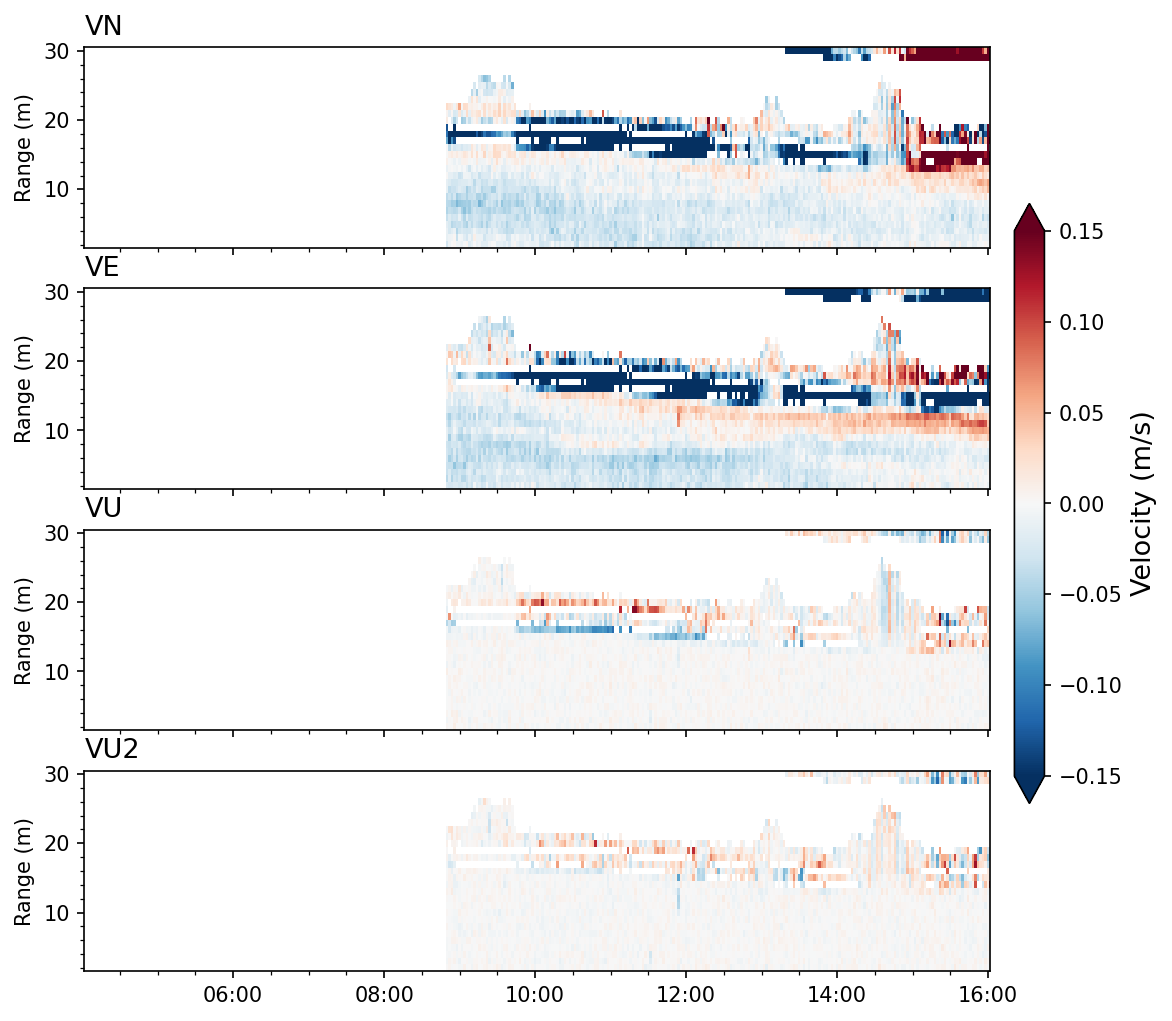

In [38]:
import datetime as dt
from source import plot
reload(plot)

xlim = [dt.timedelta(hours=-12), dt.timedelta(hours=0)]
#xlim = [dt.datetime(2025, 7, 3, 20, 20), dt.datetime(2025, 7, 3, 20, 40)]

#fig = plot.plot_data(ds_disk, plot_type=4, y_mode='range')
fig = plot.plot_data(ds_disk, plot_type=0, y_mode='range',clim=0.15, xlim=xlim, cmap='RdBu_r')
### split the vertical velocities
#fig = plot.plot_data(ds_disk, plot_type=6, y_mode='range',clim=0.01,cmap='RdBu')


display(fig)

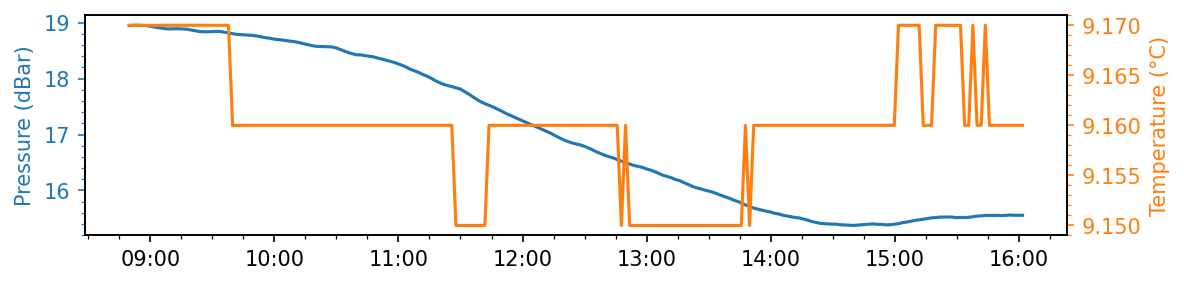

In [16]:

#xlim = [dt.timedelta(hours=-2), dt.timedelta(hours=0)]
#xlim = [dt.datetime(2025, 7, 3, 20, 20), dt.datetime(2025, 7, 3, 20, 40)]

fig = plot.plot_data(ds_disk, plot_type=4, y_mode='range')
#fig = plot.plot_data(ds_disk, plot_type=0, y_mode='range',clim=0.15, cmap='RdBu')
### split the vertical velocities
#fig = plot.plot_data(ds_disk, plot_type=6, y_mode='range',clim=0.01,cmap='RdBu')


display(fig)

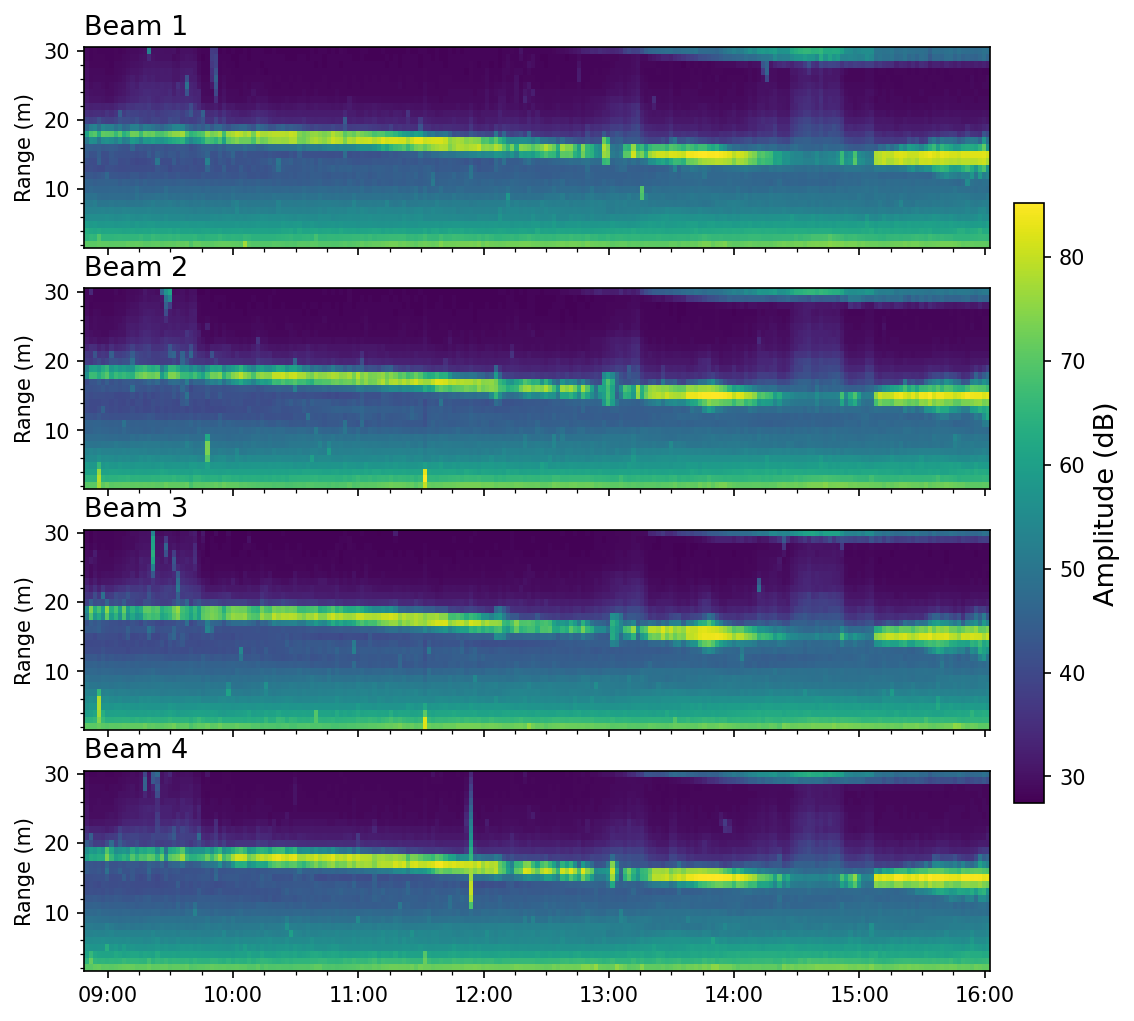

In [18]:

#xlim = [dt.timedelta(hours=-36), dt.timedelta(hours=0)]
#xlim = [dt.datetime(2025, 7, 3, 20, 20), dt.datetime(2025, 7, 3, 20, 40)]

fig = plot.plot_data(ds_disk, plot_type=1, y_mode='range')
#fig = plot.plot_data(ds_disk, plot_type=6, y_mode='range',clim=0.025, xlim=xlim, cmap='RdBu_r')
### split the vertical velocities
#fig = plot.plot_data(ds_disk, plot_type=6, y_mode='range',clim=0.01,cmap='RdBu')


display(fig)

In [19]:
ds_disk

<xarray.Dataset> Size: 691kB
Dimensions:  (TIME: 217, CN: 29)
Coordinates:
  * TIME     (TIME) datetime64[ns] 2kB 2025-10-11T08:49:48 ... 2025-10-11T16:...
  * CN       (CN) float64 232B 1.0 2.0 3.0 4.0 5.0 ... 25.0 26.0 27.0 28.0 29.0
Data variables: (12/33)
    CP       (TIME, CN) float64 50kB ...
    VE       (TIME, CN) float64 50kB -0.023 -0.041 -0.033 ... nan -0.56 -0.292
    VN       (TIME, CN) float64 50kB -0.028 -0.012 -0.011 ... nan 0.444 0.308
    VU       (TIME, CN) float64 50kB 0.003 -0.005 0.004 ... nan -0.042 -0.02
    VU2      (TIME, CN) float64 50kB 0.0 -0.004 -0.002 ... nan -0.041 0.015
    A1       (TIME, CN) float64 50kB 70.7 64.5 63.2 59.4 ... 28.1 31.9 46.1 48.5
    ...       ...
    T        (TIME) float64 2kB 9.17 9.17 9.17 9.17 9.17 ... 9.16 9.16 9.16 9.16
    IT       (TIME) float64 2kB ...
    NB       (TIME) float64 2kB ...
    NC       (TIME) float64 2kB ...
    BD       (TIME) float64 2kB ...
    CS       (TIME) float64 2kB ...

In [20]:
ds=ds_disk

In [21]:
ds['CP']

<xarray.DataArray 'CP' (TIME: 217, CN: 29)> Size: 50kB
[6293 values with dtype=float64]
Coordinates:
  * TIME     (TIME) datetime64[ns] 2kB 2025-10-11T08:49:48 ... 2025-10-11T16:...
  * CN       (CN) float64 232B 1.0 2.0 3.0 4.0 5.0 ... 25.0 26.0 27.0 28.0 29.0

In [22]:
def resolve_key(key, index, name):
    # Convert key (int) to string
    if key in index.keys():
        return index[key]
    # If key is already a string
    elif key in index.values():
        return key
    else:
        # Handle incorrect values
        raise ValueError(f'{repr(key)} is not a valid value for {name}; available values are: {index}')



In [23]:
def get_x_data(x_mode, ds):
    x_modes = {0: 'time', 1: 'index'}
    x_mode = resolve_key(x_mode, x_modes, 'x_mode')
    x = ds['TIME'] if x_mode == 'time' else list(range(len(ds['TIME'])))

    return x, x_mode



In [24]:
x, x_mode = get_x_data('time', ds)


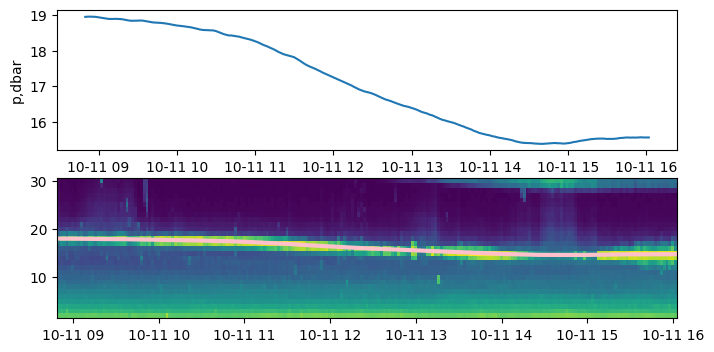

In [27]:
fig, axs = plt.subplots(2, 1, figsize=(8, 4))

# Plot heading, pitch, roll data
ax1 = axs[0]
y1 = ds['P']
ax1.plot(x, y1)
ax1.set_ylabel('p,dbar')
ax2 = axs[1]
y =  ds['CP']
Z = ds['A1'].T
cmesh = ax2.pcolormesh(x,y[1,:], Z, cmap='viridis')
ax2.plot(x,0.95*y1,color='pink',linewidth=3)



In [28]:
Z.shape

(29, 217)

In [54]:
line = 0.9*y1
masked_data=Z.copy() #np.zeros_like(Z)
for i, threshold in enumerate(line):
    masked_data[int(threshold):, i] = np.nan #np.where(Z[:,i] > threshold, np.nan, Z[:,i])


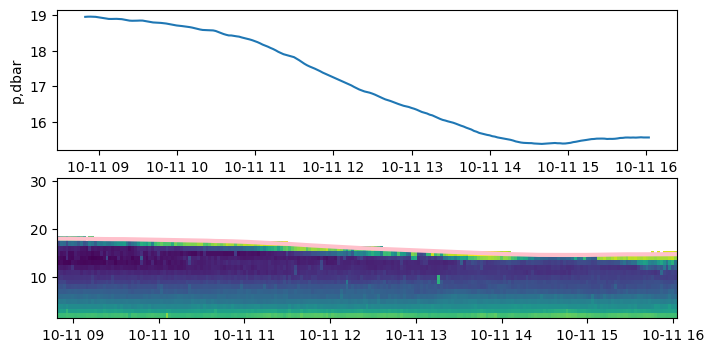

In [55]:
fig, axs = plt.subplots(2, 1, figsize=(8, 4))

# Plot heading, pitch, roll data
ax1 = axs[0]
y1 = ds['P']
ax1.plot(x, y1)
ax1.set_ylabel('p,dbar')
ax2 = axs[1]
y =  ds['CP']
Z = ds['A1'].T
cmesh = ax2.pcolormesh(x,y[1,:], masked_data, cmap='viridis')
ax2.plot(x,0.95*y1,color='pink',linewidth=3)


In [76]:
#### making universal mask
line = 0.5*y1
mask=np.ones_like(Z)


#m3 = []
#m5 = []

for i, threshold in enumerate(line):
    thresh = int(threshold)
#    thresh_m3 = thresh - 3
#    thresh_m5 = thresh - 5
    mask[thresh:, i] = np.nan #np.where(Z[:,i] > threshold, np.nan, Z[:,i])
#    m3.append(Z[thresh_m3, i])
#    m5.append(Z[thresh_m5,i])

In [81]:
def mask_35(field,ptide, threshold_scale):
     
    Z = field
    line = threshold_scale*ptide
    mask=np.ones_like(Z)


    m3 = []
    m5 = []

    for i, threshold in enumerate(line):
        thresh = int(threshold)
        thresh_m3 = thresh - 2
        thresh_m5 = thresh - 4
        mask[thresh:, i] = np.nan #np.where(Z[:,i] > threshold, np.nan, Z[:,i])
        m3.append(np.nanmean(Z[thresh_m3:thresh+1, i]))
        m5.append(np.nanmean(Z[thresh_m5:thresh+1,i]))
    return m3,m5, mask

In [71]:
thresh0 = 5
np.arange(10)[thresh0-2:thresh0+1]

array([3, 4, 5])

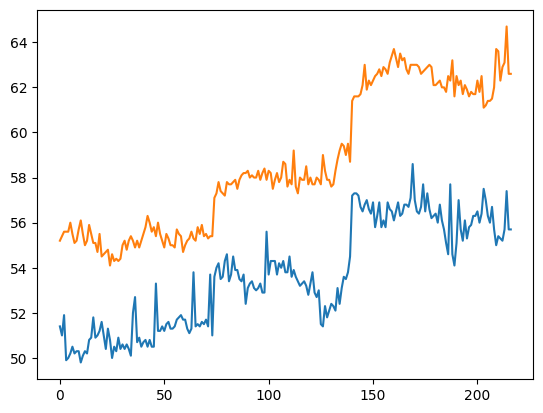

In [72]:
plt.plot(m3)
plt.plot(m5)

In [82]:
v3,v5, mask = mask_35(ds['VN'].T,ds['P'], threshold_scale=0.8)
u3,u5, mask = mask_35(ds['VE'].T,ds['P'], threshold_scale=0.8)


In [95]:
x[-1] - np.timedelta64(6,'h')

<xarray.DataArray 'TIME' ()> Size: 8B
array('2025-10-11T10:01:48.000000000', dtype='datetime64[ns]')
Coordinates:
    TIME     datetime64[ns] 8B 2025-10-11T16:01:48

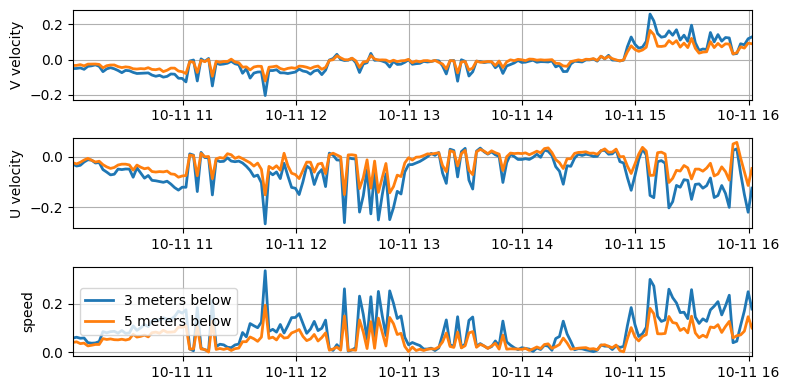

In [103]:

fig, axs = plt.subplots(3, 1, figsize=(8, 4))

# Plot heading, pitch, roll data
ax1 = axs[0]
ax1.plot(x,v3,linewidth=2,label='3 meters below')
ax1.plot(x,v5,linewidth=2,label='5 meters below')
ax1.grid(True)
ax1.set_xlim(x[-1] - np.timedelta64(6,'h'),x[-1])
ax1.set_ylabel('V velocity')
ax2 = axs[1]
ax2.plot(x,u3,linewidth=2,label='3 meters below')
ax2.plot(x,u5,linewidth=2,label='5 meters below')
ax2.grid(True)
ax2.set_ylabel('U velocity')

ax2.set_xlim(x[-1] - np.timedelta64(6,'h'),x[-1])

uv3 = (np.array(u3)**2 + np.array(v3)**2)**0.5
uv5 = (np.array(u5)**2 + np.array(v5)**2)**0.5

ax3 = axs[2]
ax3.plot(x,uv3,linewidth=2,label='3 meters below')
ax3.plot(x,uv5,linewidth=2,label='5 meters below')
ax3.grid(True)
ax3.legend(loc='center left')
ax3.set_ylabel('speed')
ax3.set_xlim(x[-1] - np.timedelta64(6,'h'),x[-1])
plt.tight_layout()

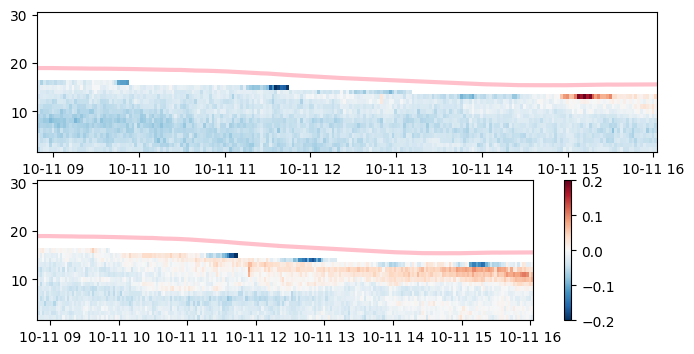

In [85]:
fig, axs = plt.subplots(2, 1, figsize=(8, 4))

# Plot heading, pitch, roll data
ax1 = axs[0]
Z1 = ds['VN'].T*mask
ax1.pcolormesh(x,y[1,:],Z1 , cmap='RdBu_r')
ax1.plot(x,y1,color='pink',linewidth=3)
ax2 = axs[1]
Z2 = ds['VE'].T*mask
cax = ax2.pcolormesh( x,y[1,:],Z2 , cmap='RdBu_r', vmin=-0.2, vmax=0.2)
ax2.plot(x,y1,color='pink',linewidth=3)

fig.colorbar(cax)#, ax=axes[0])  # 👈 Colorbar only for subplot 0

In [22]:
filename = ifile.rpartition('/')[-1].split('.')[0]

fig.savefig(f'plots/{filename}_correlation.png', bbox_inches='tight')

## Report figure

In [199]:
fig.savefig(f'plots/averaging_interval.png', bbox_inches='tight')

## Tests

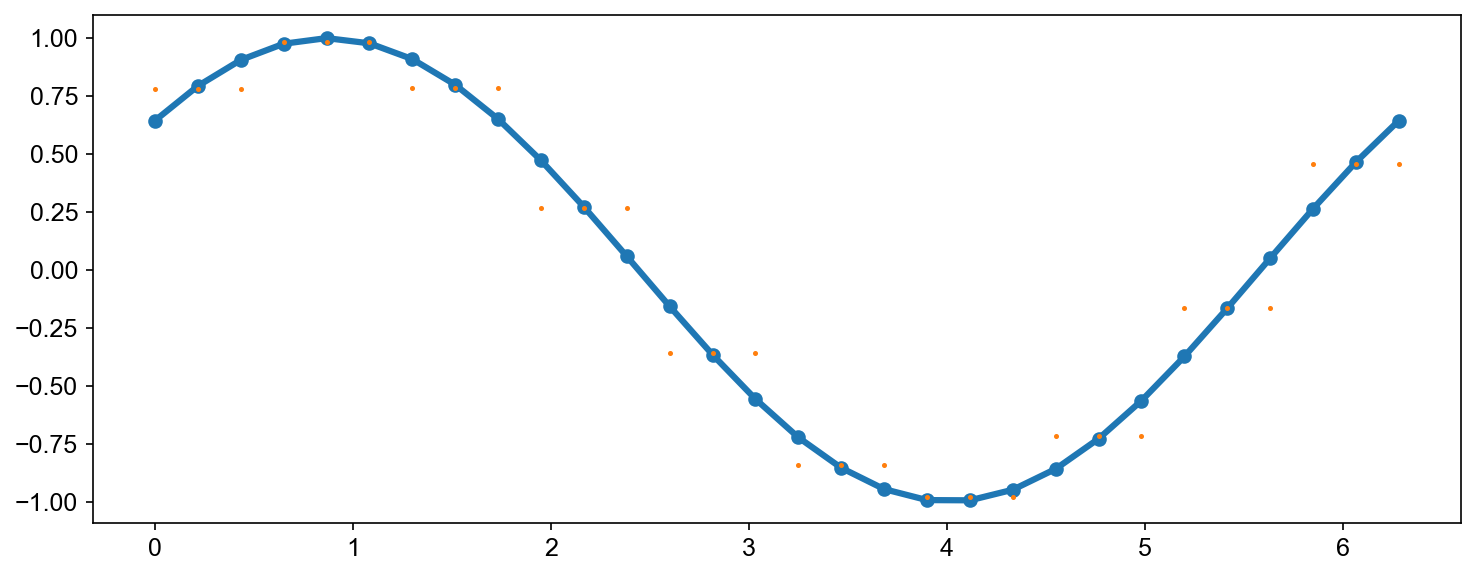

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Create a 2D array using sine functions
x = np.linspace(0, 2 * np.pi, 30)
arr = np.sin(x+0.7)

# Averaging function
def average_pixels(arr, xpixavg=1, ypixavg=1):
    is_1d = arr.ndim == 1
    arr = np.atleast_2d(arr)

    ny, nx = arr.shape
    ny_crop = ny - ny % ypixavg
    nx_crop = nx - nx % xpixavg

    arr_cropped = arr[:ny_crop, :nx_crop]
    reshaped = arr_cropped.reshape(ny_crop // ypixavg, ypixavg, nx_crop // xpixavg, xpixavg)
    block_avg = reshaped.mean(axis=(1, 3))
    upscaled = np.kron(block_avg, np.ones((ypixavg, xpixavg)))

    # Pad to original size
    result = np.full_like(arr, np.nan, dtype=float)
    result[:upscaled.shape[0], :upscaled.shape[1]] = upscaled

    return result.squeeze() if is_1d else result


# Apply averaging
arr_avg = average_pixels(arr, xpixavg=3, ypixavg=1)

# Plot original and averaged arrays
fig, ax = plt.subplots(figsize=(10, 4), dpi=150)
ax.plot(x, arr, marker='o', lw=3)
ax.scatter(x, arr_avg, c='tab:orange', s=2,zorder=3)
plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt

ds = ds_disk
PT_colors = ['tab:blue', 'tab:orange']

fig = plt.figure(figsize=(8, 2), dpi=150)
ax1 = fig.add_subplot()
ax2 = ax1.twinx()

# Plot pressure
ax1.plot(ds['TIME'], ds['P'], color=PT_colors[0])

# Plot temperature
ax2.plot(ds['TIME'], ds['T'], color=PT_colors[1])

ax1.set_ylabel('Pressure (dBar)', color=PT_colors[0])
ax1.tick_params(which='both', axis='y', colors=PT_colors[0])

ax2.set_ylabel('Temperature (°C)', color=PT_colors[1])
ax2.tick_params(which='both', axis='y', colors=PT_colors[1])

ax1.minorticks_on()
ax2.minorticks_on()
